# Online Retail — Business Questions and Sales Analysis
**Complete portfolio project | Descriptive analytics (not machine learning)**

**Dataset:** UCI Online Retail, UK-based retailer, 2010–2011. **Grain:** each row represents one invoice product line. An invoice may have multiple lines; customer summaries use one row per identified customer.

**Roadmap:** quality audit → clean sales → transaction features → customer RFM → product/time/country analysis → relationships → co-purchase → outliers → evidence-based findings → dashboard. Run all cells in order. The source file `online_retail.csv.gz` must be in the same folder.

## 1. Business context and questions
Which customers generate revenue? Which products and markets lead sales? When does demand peak? Which product pairs are bought together? How should the business act on the evidence?

In [1]:
from pathlib import Path
from itertools import combinations
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 40)
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
RAW = Path('online_retail.csv.gz')
if not RAW.exists(): raise FileNotFoundError('Place online_retail.csv.gz next to this notebook')
df_raw = pd.read_csv(RAW, compression='gzip', dtype={'InvoiceNo':str,'StockCode':str})
df_raw['InvoiceDate'] = pd.to_datetime(df_raw['InvoiceDate'], errors='coerce')
print('Raw shape:', df_raw.shape)
display(df_raw.head())

Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Data understanding
Invoice lines, invoices, products and identified customers are distinct units. Check coverage before aggregating.

In [2]:
display(df_raw.info())
display(df_raw[['Quantity','UnitPrice']].describe())
profile = pd.Series({'rows':len(df_raw),'invoices':df_raw.InvoiceNo.nunique(), 'customers_identified':df_raw.CustomerID.nunique(), 'products':df_raw.StockCode.nunique(), 'countries':df_raw.Country.nunique(), 'first_date':df_raw.InvoiceDate.min(), 'last_date':df_raw.InvoiceDate.max()})
display(profile.to_frame('value'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


None

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


,value
rows,541909
invoices,25900
customers_identified,4372
products,4070
countries,38
first_date,2010-12-01 08:26:00
last_date,2011-12-09 12:50:00


## 3. Data quality investigation and cleaning
Cancellations (invoice numbers starting with C), zero/negative prices, negative quantities and non-merchandise codes are examined separately. Legitimate wholesale purchases are not removed simply for being large. Missing customer IDs remain in overall sales but not customer-level analysis. Cancellations are excluded from *gross positive sales*; this is **not net revenue**.

In [3]:
NON_PRODUCT_CODES = {'POST','D','M','CRUK','DOT','BANK CHARGES','S','C2','PADS','AMAZONFEE'}
quality = pd.Series({
 'raw_rows':len(df_raw), 'exact_duplicate_rows':int(df_raw.duplicated().sum()),
 'missing_customer_id':int(df_raw.CustomerID.isna().sum()),
 'missing_description':int(df_raw.Description.isna().sum()),
 'invalid_dates':int(df_raw.InvoiceDate.isna().sum()),
 'cancellation_lines':int(df_raw.InvoiceNo.str.startswith('C',na=False).sum()),
 'nonpositive_quantity':int((df_raw.Quantity<=0).sum()),
 'nonpositive_price':int((df_raw.UnitPrice<=0).sum()),
 'non_product_lines':int(df_raw.StockCode.str.upper().isin(NON_PRODUCT_CODES).sum())})
display(quality.to_frame('count'))
all_lines = df_raw.drop_duplicates().copy()
all_lines['IsCanceled'] = all_lines.InvoiceNo.str.startswith('C',na=False)
all_lines['IsNonProduct'] = all_lines.StockCode.str.upper().isin(NON_PRODUCT_CODES)
all_lines['Description'] = all_lines.Description.fillna('Unknown')
valid = (~all_lines.IsCanceled & ~all_lines.IsNonProduct & (all_lines.Quantity>0) & (all_lines.UnitPrice>0) & all_lines.InvoiceDate.notna())
df_sales = all_lines.loc[valid].copy()
print('Retained positive merchandise lines:',len(df_sales))
quality.to_csv(OUT/'quality_audit.csv',header=['count'])

,count
raw_rows,541909
exact_duplicate_rows,5268
missing_customer_id,135080
missing_description,1454
invalid_dates,0
cancellation_lines,9288
nonpositive_quantity,10624
nonpositive_price,2517
non_product_lines,2913


Retained positive merchandise lines: 522569


## 4. Transaction features
Revenue = Quantity × UnitPrice. Date parts allow monthly, weekday and hourly analysis.

In [4]:
df_sales['Revenue'] = df_sales.Quantity * df_sales.UnitPrice
dt = df_sales.InvoiceDate.dt
df_sales['Year'] = dt.year
df_sales['Month'] = dt.to_period('M').astype(str)
df_sales['Weekday'] = dt.day_name()
df_sales['WeekdayIndex'] = dt.dayofweek
df_sales['Hour'] = dt.hour
df_sales['IsWeekend'] = dt.dayofweek >= 5
print('Gross positive merchandise sales (£):',round(df_sales.Revenue.sum(),2))
display(df_sales.head(3))

Gross positive merchandise sales (£): 10258967.19


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCanceled,IsNonProduct,Revenue,Year,Month,Weekday,WeekdayIndex,Hour,IsWeekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,False,15.30,2010,2010-12,Wednesday,2,8,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,20.34,2010,2010-12,Wednesday,2,8,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,False,22.00,2010,2010-12,Wednesday,2,8,False


## 5. Customer-level feature table
Only identified customers are used for customer metrics. Frequency counts distinct invoices, not line items.

In [5]:
cust_sales = df_sales.dropna(subset=['CustomerID']).copy()
snapshot = df_sales.InvoiceDate.max()+pd.Timedelta(days=1)
customer_df = cust_sales.groupby('CustomerID').agg(
 total_revenue=('Revenue','sum'), num_of_orders=('InvoiceNo','nunique'),
 num_of_items=('Quantity','sum'), unique_products=('StockCode','nunique'),
 first_purchase=('InvoiceDate','min'),last_purchase=('InvoiceDate','max'),
 country=('Country','first')).reset_index()
customer_df['average_order_value']=customer_df.total_revenue/customer_df.num_of_orders
customer_df['recency']=(snapshot-customer_df.last_purchase).dt.days
customer_df['lifetime_days']=(customer_df.last_purchase-customer_df.first_purchase).dt.days
customer_df['average_days_between_orders']=np.where(customer_df.num_of_orders>1,customer_df.lifetime_days/(customer_df.num_of_orders-1),np.nan)
display(customer_df.head())

,CustomerID,total_revenue,num_of_orders,num_of_items,unique_products,first_purchase,last_purchase,country,average_order_value,recency,lifetime_days,average_days_between_orders
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00,2011-01-18 10:01:00,United Kingdom,77183.600000,326,0,NaN
1,12347.0,4310.00,7,2458,103,2010-12-07 14:57:00,2011-12-07 15:52:00,Iceland,615.714286,2,365,60.833333
2,12348.0,1437.24,4,2332,21,2010-12-16 19:09:00,2011-09-25 13:13:00,Finland,359.310000,75,282,94.000000
3,12349.0,1457.55,1,630,72,2011-11-21 09:51:00,2011-11-21 09:51:00,Italy,1457.550000,19,0,NaN
4,12350.0,294.40,1,196,16,2011-02-02 16:01:00,2011-02-02 16:01:00,Norway,294.400000,310,0,NaN


## 6. RFM segmentation
Recency (lower better), Frequency and Monetary (higher better) receive rank-based quintile scores. These are descriptive, rule-based segments, not a churn prediction model.

,Customers,Revenue,Customer_Share,Revenue_Share
Segment,,,,
Champions,940,5647250.42,21.69,64.63
Loyal Customers,510,910715.05,11.77,10.42
At Risk,467,753263.36,10.78,8.62
Hibernating,1078,515889.91,24.87,5.90
Potential Loyalists,482,490916.02,11.12,5.62
Need Attention,857,419192.88,19.77,4.80


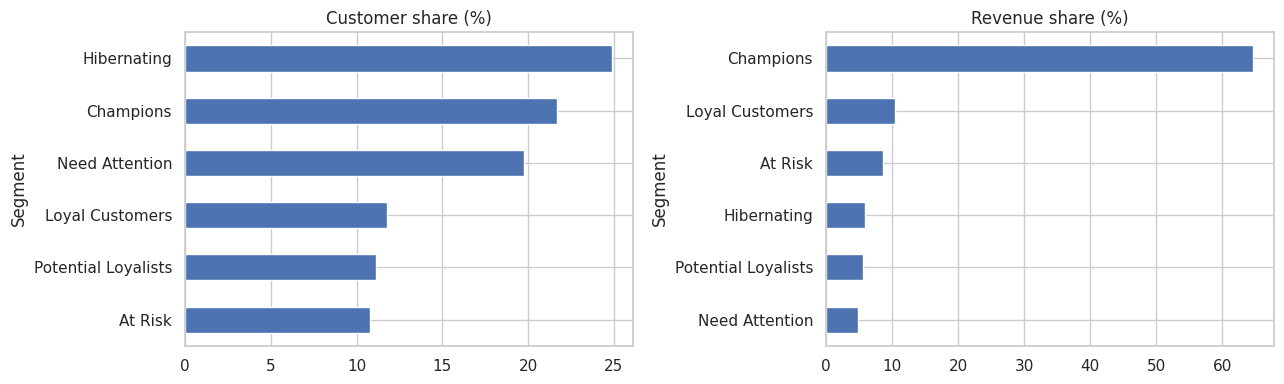

In [6]:
rfm=customer_df[['CustomerID','recency','num_of_orders','total_revenue']].rename(columns={'recency':'Recency','num_of_orders':'Frequency','total_revenue':'Monetary'}).copy()
for col,ascending,letter in [('Recency',False,'R'),('Frequency',True,'F'),('Monetary',True,'M')]:
    rfm[letter]=pd.qcut(rfm[col].rank(method='first',ascending=ascending),5,labels=[1,2,3,4,5]).astype(int)
rfm['RFM_Sum']=rfm[['R','F','M']].sum(axis=1)
def segment(row):
 r,f,m = int(row.R),int(row.F),int(row.M)
 if r>=4 and f>=4 and m>=4: return 'Champions'
 if r>=3 and f>=4: return 'Loyal Customers'
 if r>=4 and f>=2: return 'Potential Loyalists'
 if r<=2 and f>=3 and m>=3: return 'At Risk'
 if r<=2 and f<=2: return 'Hibernating'
 return 'Need Attention'
rfm['Segment']=rfm.apply(segment,axis=1)
customer_df=customer_df.merge(rfm[['CustomerID','R','F','M','RFM_Sum','Segment']],on='CustomerID',validate='one_to_one')
segment_summary=customer_df.groupby('Segment').agg(Customers=('CustomerID','size'),Revenue=('total_revenue','sum')).sort_values('Revenue',ascending=False)
segment_summary['Customer_Share']=100*segment_summary.Customers/segment_summary.Customers.sum()
segment_summary['Revenue_Share']=100*segment_summary.Revenue/segment_summary.Revenue.sum()
display(segment_summary.round(2))
fig,axes=plt.subplots(1,2,figsize=(13,4))
segment_summary.Customer_Share.sort_values().plot.barh(ax=axes[0],title='Customer share (%)')
segment_summary.Revenue_Share.sort_values().plot.barh(ax=axes[1],title='Revenue share (%)')
plt.tight_layout();plt.savefig(OUT/'rfm_segments.png',dpi=160);plt.show()

## 7. Product analysis
Product quantity leaders are not necessarily revenue leaders. Group by stock code to avoid treating inconsistent descriptions as distinct products.

,Description,Units,Revenue,Invoices
StockCode,,,,
22423,REGENCY CAKESTAND 3 TIER,13851,174156.54,1988
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75,2198
47566,PARTY BUNTING,18283,99445.23,1685
85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
23084,RABBIT NIGHT LIGHT,30739,66870.03,994
22086,PAPER CHAIN KIT 50'S CHRISTMAS,19329,64875.59,1160
84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455


Top units:


,Description,Units,Revenue,Invoices
StockCode,,,,
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
22197,POPCORN HOLDER,56898,51334.47,1392
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,535
85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75,2198
21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,1320
84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455
23084,RABBIT NIGHT LIGHT,30739,66870.03,994


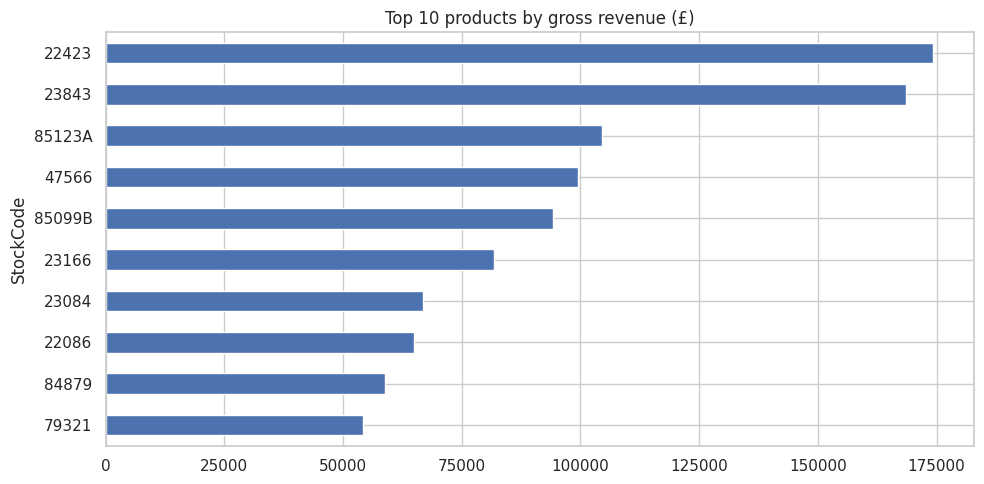

In [7]:
product_summary=df_sales.groupby('StockCode').agg(Description=('Description',lambda x:x.mode().iloc[0] if not x.mode().empty else 'Unknown'),Units=('Quantity','sum'),Revenue=('Revenue','sum'),Invoices=('InvoiceNo','nunique')).sort_values('Revenue',ascending=False)
display(product_summary.head(10));print('Top units:');display(product_summary.sort_values('Units',ascending=False).head(10))
fig,ax=plt.subplots(figsize=(10,5));product_summary.head(10).sort_values('Revenue').plot.barh(y='Revenue',ax=ax,legend=False,title='Top 10 products by gross revenue (£)');plt.tight_layout();plt.savefig(OUT/'top_products.png',dpi=160);plt.show()
product_summary.to_csv(OUT/'product_summary.csv')

## 8. Time analysis
The dataset starts in December 2010 and ends in December 2011 (partial months); compare partial months cautiously. Weekday and hourly patterns describe observed transactions, not normalized customer traffic.

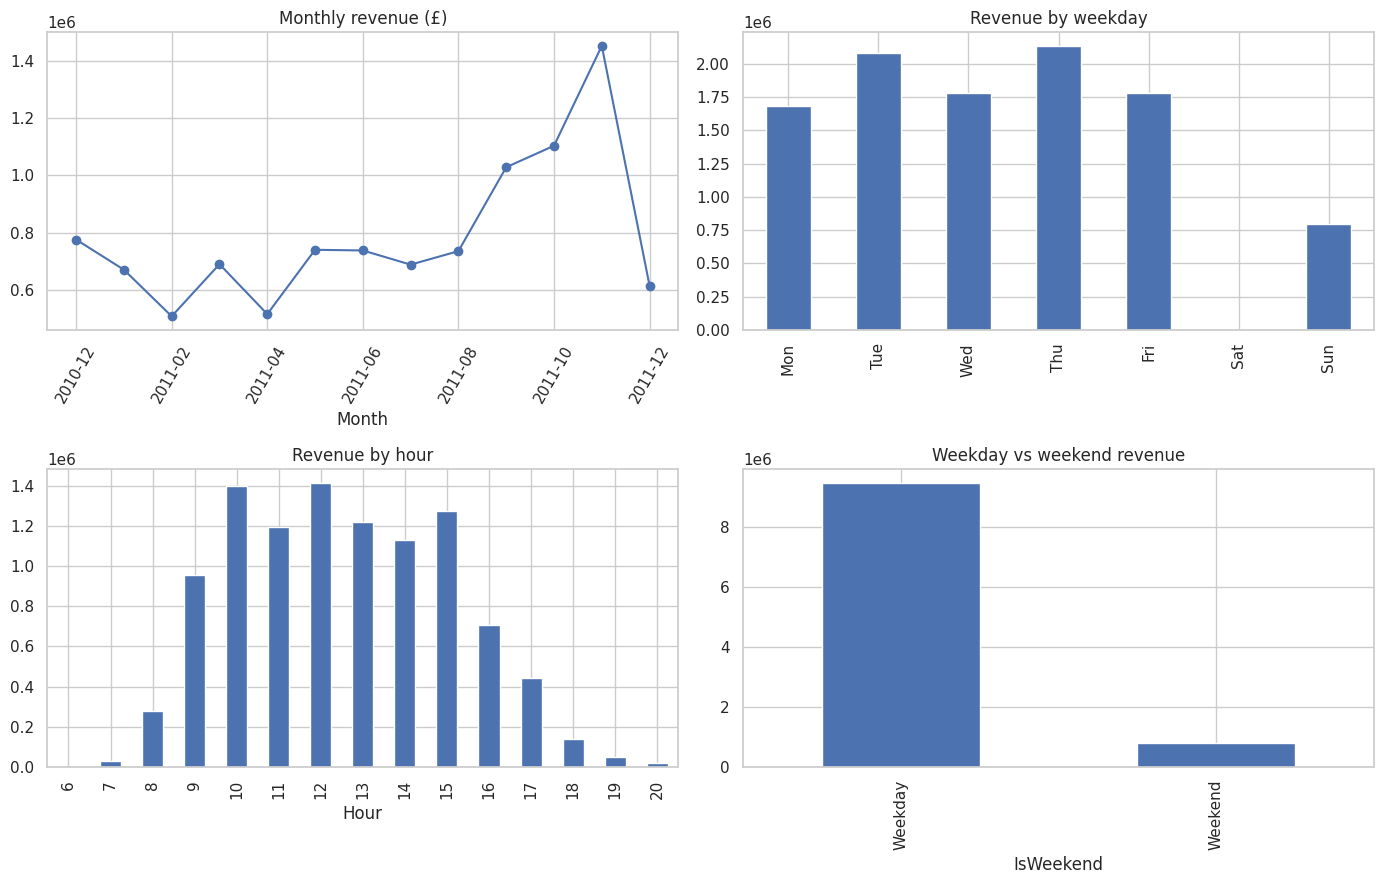

,Revenue,Invoices
IsWeekend,,
False,9460655.69,17571
True,798311.50,2203


In [8]:
monthly=df_sales.groupby('Month').Revenue.sum().sort_index()
weekday=df_sales.groupby('WeekdayIndex').Revenue.sum().reindex(range(7),fill_value=0)
hourly=df_sales.groupby('Hour').Revenue.sum().sort_index()
weekend=df_sales.groupby('IsWeekend').agg(Revenue=('Revenue','sum'),Invoices=('InvoiceNo','nunique'))
fig,axs=plt.subplots(2,2,figsize=(14,9))
monthly.plot(ax=axs[0,0],marker='o',title='Monthly revenue (£)');axs[0,0].tick_params(axis='x',rotation=60)
weekday.index=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'];weekday.plot.bar(ax=axs[0,1],title='Revenue by weekday')
hourly.plot.bar(ax=axs[1,0],title='Revenue by hour')
weekend.Revenue.rename(index={False:'Weekday',True:'Weekend'}).plot.bar(ax=axs[1,1],title='Weekday vs weekend revenue')
plt.tight_layout();plt.savefig(OUT/'time_analysis.png',dpi=160);plt.show()
display(weekend)

## 9. Country analysis
Show both revenue and invoice-level average order value (AOV); the latter must not be calculated by averaging invoice lines.

,Revenue,Invoices,Customers,Revenue_per_Invoice_approx,AOV
Country,,,,,
United Kingdom,8736191.54,17902,3916,488.000868,488.000868
Netherlands,283889.34,93,9,3052.573548,3052.573548
EIRE,270850.86,282,3,960.464043,960.464043
Germany,205381.15,443,94,463.614334,463.614334
France,184493.00,382,87,482.965969,482.965969
Australia,138103.81,56,9,2466.139464,2466.139464
Spain,55706.56,88,30,633.029091,633.029091
Switzerland,53065.60,50,21,1061.312000,1061.312000
Japan,37416.37,19,8,1969.282632,1969.282632


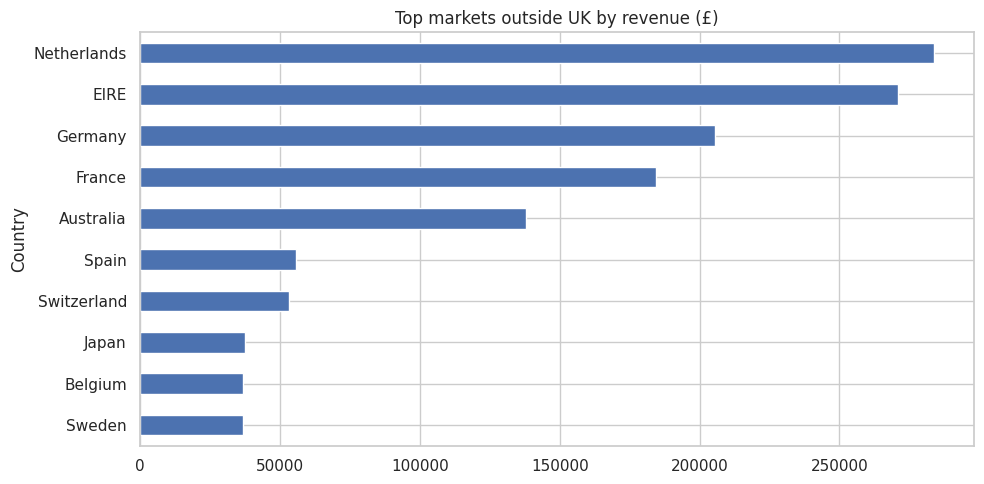

In [9]:
country_summary=df_sales.groupby('Country').agg(Revenue=('Revenue','sum'),Invoices=('InvoiceNo','nunique'),Customers=('CustomerID','nunique')).sort_values('Revenue',ascending=False)
country_summary['Revenue_per_Invoice_approx']=country_summary.Revenue/country_summary.Invoices
# For precise country AOV, aggregate to (country, invoice) first.
country_invoice=df_sales.groupby(['Country','InvoiceNo'],as_index=False).Revenue.sum()
country_summary['AOV']=country_invoice.groupby('Country').Revenue.mean()
display(country_summary.head(12))
non_uk=country_summary.drop(index='United Kingdom',errors='ignore').head(10)
ax=non_uk.Revenue.sort_values().plot.barh(title='Top markets outside UK by revenue (£)',figsize=(10,5));plt.tight_layout();plt.savefig(OUT/'countries.png',dpi=160);plt.show()
country_summary.to_csv(OUT/'country_summary.csv')

## 10. Customer behavior relationships
Correlation describes association, not causation. Order count and total revenue can be mechanically associated because revenue accumulates across orders.

,recency,num_of_orders,total_revenue,average_order_value,unique_products
recency,1.00,-0.56,-0.48,-0.13,-0.46
num_of_orders,-0.56,1.00,0.81,0.16,0.65
total_revenue,-0.48,0.81,1.00,0.68,0.72
average_order_value,-0.13,0.16,0.68,1.00,0.41
unique_products,-0.46,0.65,0.72,0.41,1.00


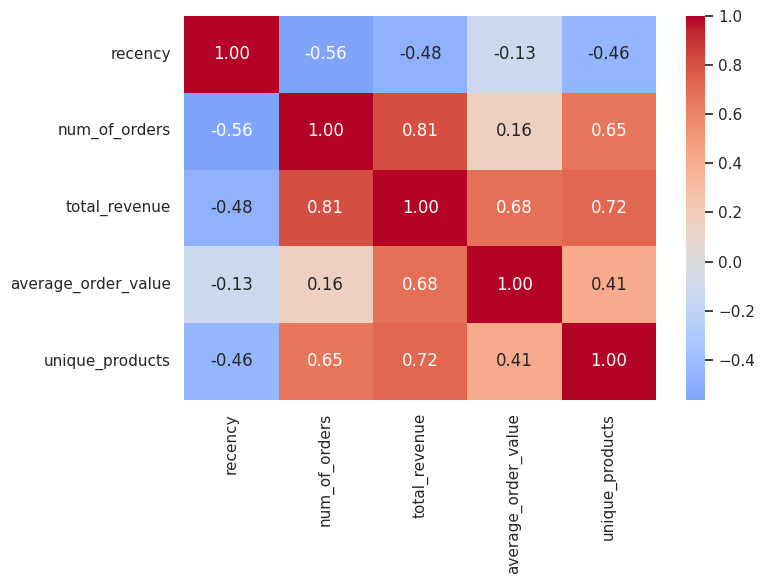

In [10]:
corr_cols=['recency','num_of_orders','total_revenue','average_order_value','unique_products']
corr=customer_df[corr_cols].corr(method='spearman')
display(corr.round(2))
fig,ax=plt.subplots(figsize=(8,6));sns.heatmap(corr,annot=True,cmap='coolwarm',center=0,fmt='.2f',ax=ax);plt.tight_layout();plt.savefig(OUT/'customer_correlations.png',dpi=160);plt.show()

## 11. Product co-purchase analysis
Count pairs of unique stock codes per invoice. For performance and interpretability, restrict to the 40 most frequently invoiced products; pair support is measured against **all** valid sales invoices, so results are not universal across the entire catalog.

In [11]:
top_codes=set(df_sales.groupby('StockCode').InvoiceNo.nunique().nlargest(40).index)
baskets=df_sales[df_sales.StockCode.isin(top_codes)].groupby('InvoiceNo').StockCode.agg(lambda x:sorted(set(x)))
pairs=Counter(pair for basket in baskets for pair in combinations(basket,2))
num_invoices=df_sales.InvoiceNo.nunique()
co_purchase=pd.DataFrame([{'Product_A':a,'Product_B':b,'Invoices_Together':cnt,'Support':cnt/num_invoices} for (a,b),cnt in pairs.items()]).sort_values('Invoices_Together',ascending=False)
display(co_purchase.head(15))
co_purchase.head(100).to_csv(OUT/'co_purchase_pairs.csv',index=False)

,Product_A,Product_B,Invoices_Together,Support
98,22386,85099B,825,0.041721
256,22697,22699,767,0.038788
65,21931,85099B,724,0.036614
106,22411,85099B,680,0.034389
70,20725,22383,655,0.033124
66,20725,20727,641,0.032416
0,22726,22727,640,0.032366
35,20725,22384,606,0.030646
50,20727,22383,584,0.029534
169,20725,85099B,579,0.029281


## 12. Outlier review
IQR flags unusual values for investigation. It does not justify deleting large legitimate wholesale orders.

In [12]:
outlier_stats=[]
for col in ['Quantity','UnitPrice','Revenue']:
 q1,q3=df_sales[col].quantile([.25,.75]);iqr=q3-q1;lo=q1-1.5*iqr;hi=q3+1.5*iqr
 flagged=((df_sales[col]<lo)|(df_sales[col]>hi)).sum()
 outlier_stats.append({'Metric':col,'Lower_IQR':lo,'Upper_IQR':hi,'Flagged_Lines':int(flagged),'Percent':round(100*flagged/len(df_sales),2)})
outlier_table=pd.DataFrame(outlier_stats);display(outlier_table)
print('Largest positive revenue lines for manual review:');display(df_sales.nlargest(8,'Revenue')[['InvoiceNo','StockCode','Quantity','UnitPrice','Revenue']])
outlier_table.to_csv(OUT/'outlier_review.csv',index=False)

,Metric,Lower_IQR,Upper_IQR,Flagged_Lines,Percent
0,Quantity,-15.50,28.50,26815,5.13
1,UnitPrice,-3.07,8.45,35773,6.85
2,Revenue,-16.80,38.40,41125,7.87


Largest positive revenue lines for manual review:


,InvoiceNo,StockCode,Quantity,UnitPrice,Revenue
540421,581483,23843,80995,2.08,168469.60
61619,541431,23166,74215,1.04,77183.60
222680,556444,22502,60,649.50,38970.00
299982,A563185,B,1,11062.06,11062.06
348325,567423,23243,1412,5.06,7144.72
52711,540815,21108,3114,2.10,6539.40
160546,550461,21108,3114,2.10,6539.40
421601,573003,23084,2400,2.08,4992.00


## 13. Key findings — observation → evidence → implication
Findings below are computed from the dataset rather than hard-coded.

In [13]:
best_product=product_summary.iloc[0]
best_month=monthly.idxmax()
best_non_uk=non_uk.index[0]
champions=segment_summary.loc['Champions'] if 'Champions' in segment_summary.index else None
findings=[
 f'Product concentration: {product_summary.index[0]} ({best_product.Description}) generated £{best_product.Revenue:,.0f} in gross positive merchandise sales. Review inventory and margin before prioritizing.',
 f'Seasonality: {best_month} had the highest observed monthly revenue (£{monthly.max():,.0f}); check incomplete month coverage before seasonal planning.',
 f'International demand: {best_non_uk} led non-UK markets with £{non_uk.iloc[0].Revenue:,.0f} in revenue. Assess shipping costs and repeat orders.',
 f'Customer concentration: Champions represent {champions.Customer_Share:.1f}% of identified customers and {champions.Revenue_Share:.1f}% of identified-customer revenue. Consider a retention experiment.' if champions is not None else 'Review high-value RFM segments for retention opportunities.'
]
for i,f in enumerate(findings,1):print(f'{i}. {f}')
(OUT/'key_findings.txt').write_text('\n'.join(findings),encoding='utf-8')

1. Product concentration: 22423 (REGENCY CAKESTAND 3 TIER) generated £174,157 in gross positive merchandise sales. Review inventory and margin before prioritizing.
2. Seasonality: 2011-11 had the highest observed monthly revenue (£1,452,116); check incomplete month coverage before seasonal planning.
3. International demand: Netherlands led non-UK markets with £283,889 in revenue. Assess shipping costs and repeat orders.
4. Customer concentration: Champions represent 21.7% of identified customers and 64.6% of identified-customer revenue. Consider a retention experiment.


563

## 14. Limitations and additional data
- **Gross positive sales ≠ net revenue or profit:** cancellation/return lines are excluded; costs, discounts, refunds and fulfillment expenses are unavailable. Obtain return-to-original-invoice mapping and cost-of-goods data.
- **Customer identity:** many lines lack `CustomerID`, so RFM represents identified buyers only. Obtain a privacy-safe persistent identifier if available.
- **Incomplete observation window:** the first and last months are partial; use complete months for strict seasonal comparisons.
- **Country/AOV:** invoices may include operational anomalies; confirm market-level definitions before commercial decisions.
- **Co-purchase:** top-40 restriction makes pair counts exploratory, not an exhaustive market-basket analysis.
- **No causal inference or predictive model:** validate proposed actions with controlled experiments or future data.

## 15. Executive summary
The next cell generates a concise numerical summary, a recommendation and two limitations.

In [14]:
summary=(f'Analyzed {len(df_sales):,} valid positive merchandise lines across {df_sales.InvoiceNo.nunique():,} invoices; '
 f'gross positive merchandise revenue was £{df_sales.Revenue.sum():,.2f}. '
 f'Top product by revenue: {product_summary.index[0]}; peak observed month: {best_month}; leading non-UK market: {best_non_uk}. '
 'Recommendation: prioritize margin-aware product planning and test targeted retention for valuable customer segments. '
 'Limitations: sales exclude returns/cancellations and are not profit; missing customer IDs limit customer-level coverage.')
print(summary)
(OUT/'executive_summary.txt').write_text(summary,encoding='utf-8')

Analyzed 522,569 valid positive merchandise lines across 19,774 invoices; gross positive merchandise revenue was £10,258,967.19. Top product by revenue: 22423; peak observed month: 2011-11; leading non-UK market: Netherlands. Recommendation: prioritize margin-aware product planning and test targeted retention for valuable customer segments. Limitations: sales exclude returns/cancellations and are not profit; missing customer IDs limit customer-level coverage.


463

## Appendix — save reproducible output tables
The customer-level table includes identified customers only. The transaction table is valid positive merchandise lines only.

In [15]:
df_sales.to_csv(OUT/'clean_sales.csv',index=False)
customer_df.to_csv(OUT/'customer_rfm.csv',index=False)
segment_summary.to_csv(OUT/'segment_summary.csv')
monthly.rename('Revenue').to_csv(OUT/'monthly_revenue.csv')
print('Saved output tables to:',OUT.resolve())

Saved output tables to: /mnt/data/Online_Retail_Completed/outputs


## 16. Simplified sales dashboard
One static six-panel dashboard summarizes gross revenue, invoice count, monthly revenue, top products, non-UK markets and customer segments. Figures are generated from the same cleaned data and saved tables.

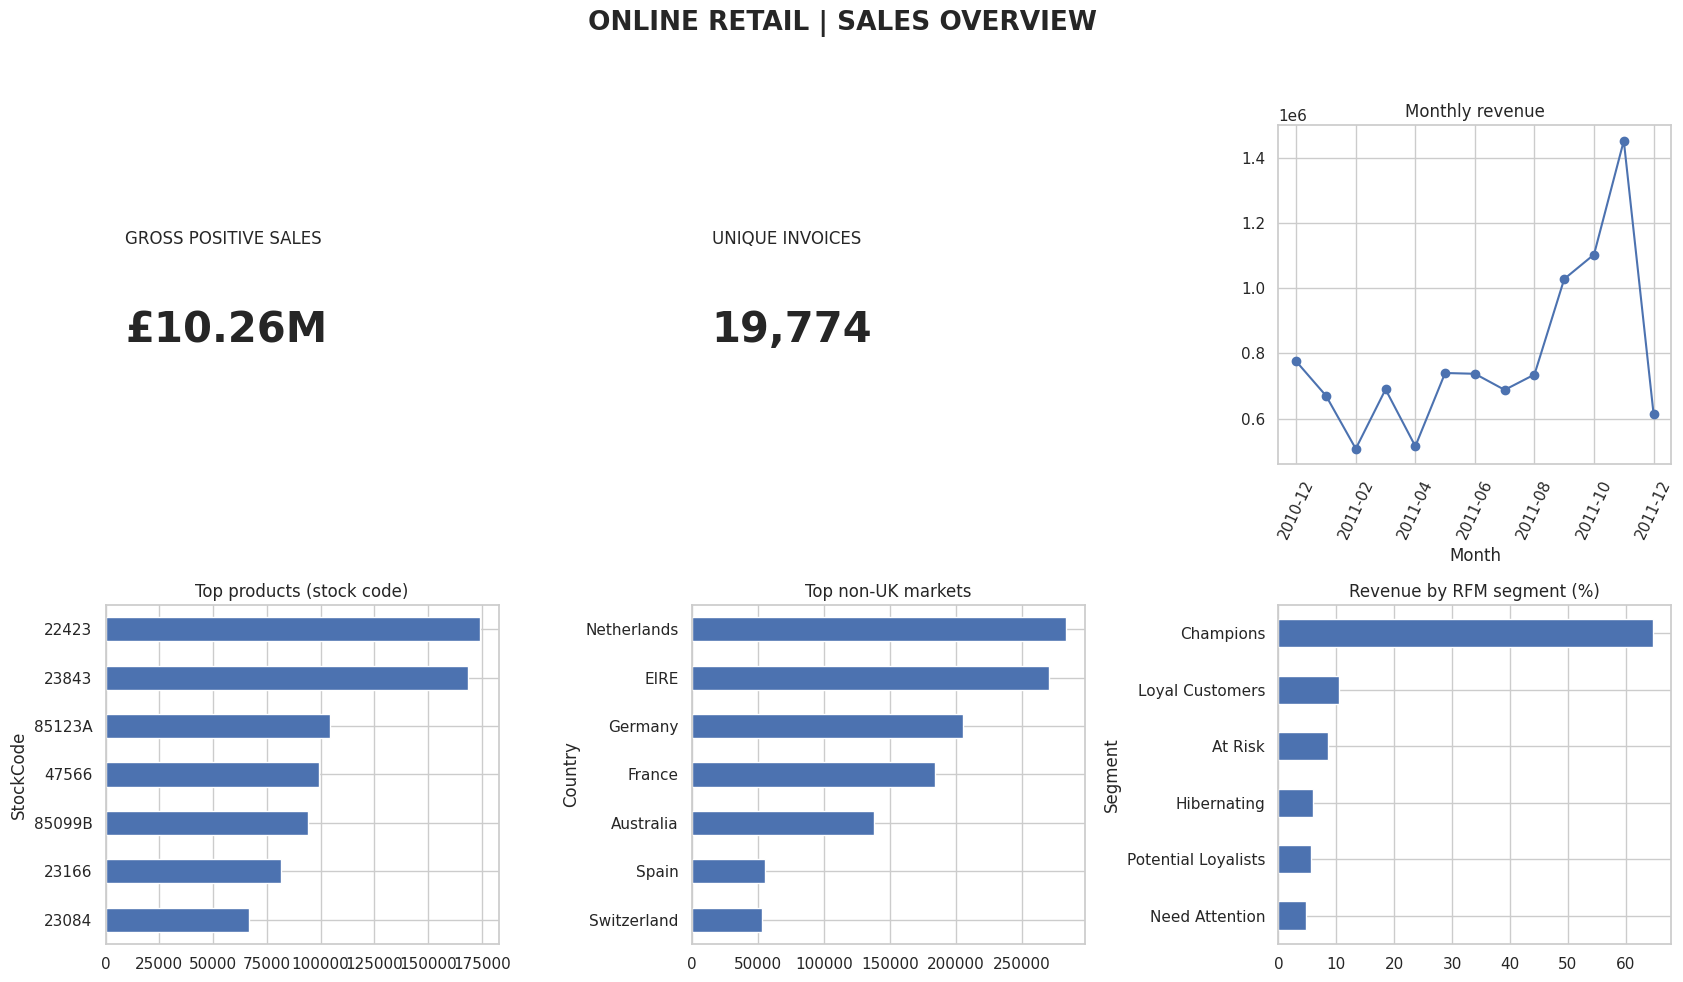

In [16]:
fig,axs=plt.subplots(2,3,figsize=(17,10));fig.suptitle('ONLINE RETAIL | SALES OVERVIEW',fontsize=19,fontweight='bold')
axs[0,0].axis('off');axs[0,0].text(.05,.65,'GROSS POSITIVE SALES',fontsize=12,transform=axs[0,0].transAxes);axs[0,0].text(.05,.36,f'£{df_sales.Revenue.sum()/1e6:,.2f}M',fontsize=30,fontweight='bold',transform=axs[0,0].transAxes)
axs[0,1].axis('off');axs[0,1].text(.05,.65,'UNIQUE INVOICES',fontsize=12,transform=axs[0,1].transAxes);axs[0,1].text(.05,.36,f'{df_sales.InvoiceNo.nunique():,}',fontsize=30,fontweight='bold',transform=axs[0,1].transAxes)
monthly.plot(ax=axs[0,2],marker='o',title='Monthly revenue');axs[0,2].tick_params(axis='x',rotation=65)
product_summary.head(7).Revenue.sort_values().plot.barh(ax=axs[1,0],title='Top products (stock code)')
non_uk.head(7).Revenue.sort_values().plot.barh(ax=axs[1,1],title='Top non-UK markets')
segment_summary.Revenue_Share.sort_values().plot.barh(ax=axs[1,2],title='Revenue by RFM segment (%)')
plt.tight_layout(rect=[0,0,1,.95]);plt.savefig(OUT/'sales_dashboard.png',dpi=170,bbox_inches='tight');plt.show()

### Dashboard interpretation
The revenue KPI is **gross positive merchandise sales**, not profit or net sales. The non-UK chart intentionally excludes the UK to make smaller markets readable. A manager could investigate the top-selling product's margin or test retention messaging for high-value customers. Neither action is proven to increase profit without cost and experiment data.